In [27]:
%pip install joblib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, RepeatedKFold, RepeatedStratifiedKFold,
                                     cross_validate, RandomizedSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor,
                              RandomForestClassifier, HistGradientBoostingClassifier)
from sklearn.svm import SVR, SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, median_absolute_error,
                             accuracy_score, f1_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

try:
    from xgboost import XGBRegressor, XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost is not installed: XGBoost will be skipped (pip install xgboost).")

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

# ---- Configuration (Appendix A of the master plan) ----
SEED = 42
TEST_SIZE = 0.20
N_SPLITS = 5
N_REPEATS = 10          # 5 x 10 = 50 evaluations per model
N_JOBS = -1
TARGET = "GPA"
CLASS_TARGET = "GradeClass"
FEATURES = ["Age", "ParentalEducation", "StudyTimeWeekly", "Absences", "Tutoring",
            "ParentalSupport", "Extracurricular", "Sports", "Music", "Volunteering"]
np.random.seed(SEED)

OUT_DIR = Path("outputs_notebook")
OUT_DIR.mkdir(exist_ok=True)
print("Setup done. xgboost available:", HAS_XGB)

Setup done. xgboost available: True


In [10]:
candidates = [Path("data/processed/students_clean.csv"), Path("students_clean_1.csv"),
              Path("/mnt/user-data/uploads/students_clean_1.csv"),
              Path("/mnt/user-data/uploads/students_clean.csv")]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Put students_clean.csv next to this notebook (looked for: " + ", ".join(str(p) for p in candidates) + ").")

df = pd.read_csv(data_path)
print("Loaded:", data_path, "| shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum(), "| StudentID unique:", df["StudentID"].is_unique)
print("Missing values:", int(df.isna().sum().sum()))
print()
print(df[[TARGET] + FEATURES].describe().T[["min", "mean", "max"]].round(3))

Loaded: data\processed\students_clean.csv | shape: (2392, 15)
Duplicate rows: 0 | StudentID unique: True
Missing values: 0

                      min    mean     max
GPA                 0.000   1.906   4.000
Age                15.000  16.469  18.000
ParentalEducation   0.000   1.746   4.000
StudyTimeWeekly     0.001   9.772  19.978
Absences            0.000  14.541  29.000
Tutoring            0.000   0.301   1.000
ParentalSupport     0.000   2.122   4.000
Extracurricular     0.000   0.383   1.000
Sports              0.000   0.304   1.000
Music               0.000   0.197   1.000
Volunteering        0.000   0.157   1.000


In [11]:
print("Observed GPA range: %.3f to %.3f" % (df[TARGET].min(), df[TARGET].max()))
print("GPA < 2.0 (F band):", int((df[TARGET] < 2.0).sum()), "students")

def gpa_to_class(gpa):
    # GradeClass coding in this dataset: 0=A (>=3.5), 1=B, 2=C, 3=D, 4=F (<2.0)
    return np.select([gpa >= 3.5, gpa >= 3.0, gpa >= 2.5, gpa >= 2.0], [0, 1, 2, 3], default=4)

df["GradeClass_from_gpa"] = gpa_to_class(df[TARGET])
mismatch = df["GradeClass_from_gpa"] != df[CLASS_TARGET]
print("\nRows where GradeClass disagrees with the GPA bands:", int(mismatch.sum()), "of", len(df))
print("Mismatches in StudentID < 3177 :", int(mismatch[df.StudentID < 3177].sum()))
print("Mismatches in StudentID >= 3177:", int(mismatch[df.StudentID >= 3177].sum()),
      "of", int((df.StudentID >= 3177).sum()))

head, tail = df[df.StudentID < 3177], df[df.StudentID >= 3177]
print("\nCorrelation of GradeClass with Absences (strong in real data, ~0.83):")
print("  first 2176 rows: %.3f" % head[CLASS_TARGET].corr(head["Absences"]))
print("  last   216 rows: %.3f   <-- GradeClass looks shuffled here" % tail[CLASS_TARGET].corr(tail["Absences"]))
print("Correlation of GPA with Absences, same two blocks: %.3f vs %.3f  (GPA is fine in both)"
      % (head[TARGET].corr(head["Absences"]), tail[TARGET].corr(tail["Absences"])))

Observed GPA range: 0.000 to 4.000
GPA < 2.0 (F band): 1274 students

Rows where GradeClass disagrees with the GPA bands: 168 of 2392
Mismatches in StudentID < 3177 : 0
Mismatches in StudentID >= 3177: 168 of 216

Correlation of GradeClass with Absences (strong in real data, ~0.83):
  first 2176 rows: 0.827
  last   216 rows: 0.052   <-- GradeClass looks shuffled here
Correlation of GPA with Absences, same two blocks: -0.918 vs -0.935  (GPA is fine in both)


In [12]:
df["GradeClass_fixed"] = df["GradeClass_from_gpa"]
print(df["GradeClass_fixed"].value_counts().sort_index().rename({0: "0 (A)", 1: "1 (B)", 2: "2 (C)", 3: "3 (D)", 4: "4 (F)"}))

GradeClass_fixed
0 (A)      77
1 (B)     244
2 (C)     385
3 (D)     412
4 (F)    1274
Name: count, dtype: int64


In [13]:
x = df[FEATURES]
y = df[TARGET]
x_dev, x_test, y_dev, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=SEED)
print("Development:", x_dev.shape, "| Test:", x_test.shape)

cv_reg = RepeatedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED)
scoring_reg = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error",
               "r2": "r2", "medae": "neg_median_absolute_error"}

def make_regressors():
    models = {
        "Dummy (mean)": DummyRegressor(strategy="mean"),
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(random_state=SEED),
        "Random Forest": RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=N_JOBS),
        "Extra Trees": ExtraTreesRegressor(n_estimators=300, random_state=SEED, n_jobs=N_JOBS),
        "HistGradientBoosting": HistGradientBoostingRegressor(random_state=SEED),
        "SVR (RBF)": make_pipeline(StandardScaler(), SVR()),
    }
    if HAS_XGB:
        models["XGBoost"] = XGBRegressor(random_state=SEED, n_jobs=N_JOBS)
    return models

fold_mae = {}   # per-fold MAE for every model (same folds), used for paired comparisons

def run_cv(label, model):
    start = time.perf_counter()
    res = cross_validate(model, x_dev, y_dev, cv=cv_reg, scoring=scoring_reg, n_jobs=1)
    secs = time.perf_counter() - start
    fold_mae[label] = -res["test_mae"]
    return {"model": label,
            "cv_mae_mean": -res["test_mae"].mean(), "cv_mae_std": res["test_mae"].std(),
            "cv_rmse_mean": -res["test_rmse"].mean(), "cv_r2_mean": res["test_r2"].mean(),
            "cv_medae_mean": -res["test_medae"].mean(), "cv_seconds": secs}

default_models = make_regressors()
rows_default = [run_cv(name, mdl) for name, mdl in default_models.items()]
cv_default = pd.DataFrame(rows_default).sort_values("cv_mae_mean").reset_index(drop=True)
cv_default.round(4)

Development: (1913, 10) | Test: (479, 10)


,model,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_r2_mean,cv_medae_mean,cv_seconds
0,Linear Regression,0.1603,0.0051,0.1975,0.9533,0.1415,0.9806
1,HistGradientBoosting,0.1778,0.0053,0.2217,0.9412,0.1507,27.2806
2,SVR (RBF),0.1816,0.0059,0.2286,0.9375,0.1509,17.2498
3,Extra Trees,0.1921,0.0079,0.2395,0.9313,0.1652,44.9673
4,Random Forest,0.1937,0.0059,0.2407,0.9307,0.1681,55.0295
5,XGBoost,0.1940,0.0072,0.2417,0.9300,0.1658,24.4473
6,Decision Tree,0.2761,0.0082,0.3464,0.8564,0.2333,1.9495
7,Dummy (mean),0.7738,0.0213,0.9164,-0.0022,0.7299,0.6808


In [14]:
search_cv = RepeatedKFold(n_splits=N_SPLITS, n_repeats=2, random_state=SEED)   # lighter folds for the search only
N_ITER = 15

grids = {
    "Decision Tree": {"max_depth": [3, 4, 5, 6, 8, 10, None],
                      "min_samples_leaf": [1, 3, 5, 10, 20, 40],
                      "min_samples_split": [2, 5, 10, 20]},
    "Random Forest": {"n_estimators": [200, 300, 500],
                      "max_depth": [None, 6, 10, 14],
                      "min_samples_leaf": [1, 2, 5, 10, 20],
                      "max_features": [0.4, 0.6, 0.8, 1.0]},
    "Extra Trees": {"n_estimators": [200, 300, 500],
                    "max_depth": [None, 6, 10, 14],
                    "min_samples_leaf": [1, 2, 5, 10, 20],
                    "max_features": [0.4, 0.6, 0.8, 1.0]},
    "HistGradientBoosting": {"learning_rate": [0.01, 0.03, 0.05, 0.1],
                             "max_iter": [100, 200, 400],
                             "max_depth": [None, 3, 5],
                             "min_samples_leaf": [10, 20, 40],
                             "l2_regularization": [0, 0.1, 1, 10]},
    "SVR (RBF)": {"svr__C": [0.1, 0.3, 1, 3, 10],
                  "svr__epsilon": [0.01, 0.05, 0.1, 0.2],
                  "svr__gamma": ["scale", 0.01, 0.03, 0.1, 0.3]},
}
if HAS_XGB:
    grids["XGBoost"] = {"n_estimators": [200, 400, 600],
                        "learning_rate": [0.01, 0.03, 0.05, 0.1],
                        "max_depth": [2, 3, 4, 6],
                        "subsample": [0.7, 0.85, 1.0],
                        "colsample_bytree": [0.7, 0.85, 1.0],
                        "min_child_weight": [1, 3, 5],
                        "reg_lambda": [1, 5, 10]}

tuned_estimators, best_params = {}, {}
for name, grid in grids.items():
    start = time.perf_counter()
    search = RandomizedSearchCV(make_regressors()[name], grid, n_iter=N_ITER, cv=search_cv,
                                scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1, refit=True)
    search.fit(x_dev, y_dev)
    tuned_estimators[name] = clone(search.best_estimator_)
    best_params[name] = {k: (v if isinstance(v, (int, float, str, type(None))) else str(v))
                         for k, v in search.best_params_.items()}
    print("%-22s search MAE %.4f | %.0fs | %s" % (name, -search.best_score_, time.perf_counter() - start, best_params[name]))

Decision Tree          search MAE 0.2398 | 3s | {'min_samples_split': 5, 'min_samples_leaf': 5, 'max_depth': 8}
Random Forest          search MAE 0.1945 | 198s | {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': 10}
Extra Trees            search MAE 0.1899 | 128s | {'n_estimators': 500, 'min_samples_leaf': 5, 'max_features': 0.6, 'max_depth': 10}
HistGradientBoosting   search MAE 0.1685 | 70s | {'min_samples_leaf': 20, 'max_iter': 400, 'max_depth': 3, 'learning_rate': 0.05, 'l2_regularization': 0}
SVR (RBF)              search MAE 0.1689 | 68s | {'svr__gamma': 0.03, 'svr__epsilon': 0.01, 'svr__C': 0.3}
XGBoost                search MAE 0.1653 | 218s | {'subsample': 0.7, 'reg_lambda': 1, 'n_estimators': 600, 'min_child_weight': 1, 'max_depth': 2, 'learning_rate': 0.03, 'colsample_bytree': 0.85}


In [15]:
rows_tuned = [run_cv(name + " (tuned)", est) for name, est in tuned_estimators.items()]
cv_tuned = pd.DataFrame(rows_tuned)

compare = []
for name in tuned_estimators:
    before = cv_default.loc[cv_default.model == name, "cv_mae_mean"].iloc[0]
    after = cv_tuned.loc[cv_tuned.model == name + " (tuned)", "cv_mae_mean"].iloc[0]
    compare.append({"model": name, "mae_default": before, "mae_tuned": after,
                    "improvement": before - after, "improvement_%": 100 * (before - after) / before})
tuning_gain = pd.DataFrame(compare).sort_values("improvement", ascending=False).reset_index(drop=True)
tuning_gain.round(4)

,model,mae_default,mae_tuned,improvement,improvement_%
0,Decision Tree,0.2761,0.2423,0.0338,12.2352
1,XGBoost,0.1940,0.1646,0.0294,15.1441
2,SVR (RBF),0.1816,0.1684,0.0132,7.2868
3,HistGradientBoosting,0.1778,0.1684,0.0093,5.2515
4,Extra Trees,0.1921,0.1890,0.0032,1.6433
5,Random Forest,0.1937,0.1938,-0.0001,-0.0601


In [16]:
candidates_reg = dict(default_models)
for name, est in tuned_estimators.items():
    candidates_reg[name + " (tuned)"] = est

def holdout_metrics(model):
    fitted = clone(model).fit(x_dev, y_dev)
    pred = fitted.predict(x_test)
    return {"test_mae": mean_absolute_error(y_test, pred),
            "test_rmse": float(np.sqrt(mean_squared_error(y_test, pred))),
            "test_r2": r2_score(y_test, pred)}

cv_all = pd.concat([cv_default, cv_tuned], ignore_index=True)
test_rows = {label: holdout_metrics(est) for label, est in candidates_reg.items()}
test_df = pd.DataFrame(test_rows).T.reset_index().rename(columns={"index": "model"})

def params_text(label):
    base = label.replace(" (tuned)", "")
    return str(best_params[base]) if label.endswith("(tuned)") else "defaults"

results = cv_all.merge(test_df, on="model")
results["selected_parameters"] = results["model"].map(params_text)
results = results.sort_values("cv_mae_mean").reset_index(drop=True)
results.insert(0, "rank", results.index + 1)

show = ["rank", "model", "cv_mae_mean", "cv_mae_std", "cv_rmse_mean", "cv_r2_mean", "test_mae", "test_rmse", "test_r2"]
results[show].round(4)

,rank,model,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_r2_mean,test_mae,test_rmse,test_r2
0,1,Linear Regression,0.1603,0.0051,0.1975,0.9533,0.1555,0.1968,0.9532
1,2,XGBoost (tuned),0.1646,0.0054,0.2035,0.9504,0.1592,0.2026,0.9504
2,3,SVR (RBF) (tuned),0.1684,0.0053,0.2095,0.9475,0.1615,0.2063,0.9485
3,4,HistGradientBoosting (tuned),0.1684,0.0052,0.2097,0.9474,0.1643,0.2097,0.9468
4,5,HistGradientBoosting,0.1778,0.0053,0.2217,0.9412,0.1766,0.2219,0.9405
5,6,SVR (RBF),0.1816,0.0059,0.2286,0.9375,0.1777,0.2276,0.9374
6,7,Extra Trees (tuned),0.1890,0.0079,0.2364,0.9331,0.1880,0.2404,0.9301
7,8,Extra Trees,0.1921,0.0079,0.2395,0.9313,0.1853,0.2383,0.9313
8,9,Random Forest,0.1937,0.0059,0.2407,0.9307,0.1847,0.2394,0.9307
9,10,Random Forest (tuned),0.1938,0.0057,0.2408,0.9306,0.1865,0.2399,0.9304


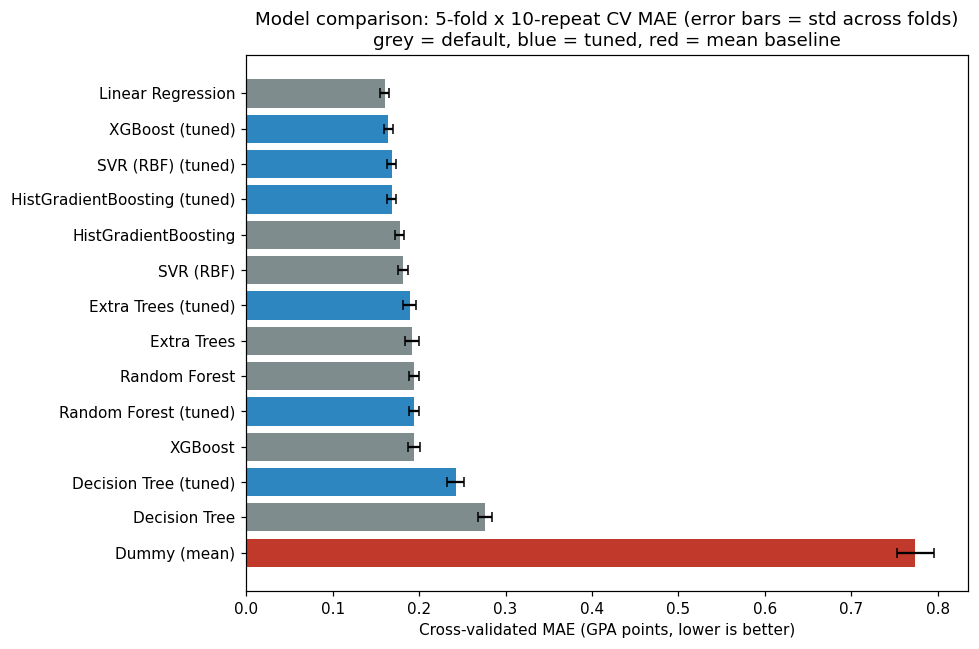

In [17]:
results.to_csv(OUT_DIR / "model_comparison.csv", index=False)

order = results.sort_values("cv_mae_mean", ascending=False)
colors = ["#c0392b" if m.startswith("Dummy") else ("#2e86c1" if "(tuned)" in m else "#7f8c8d") for m in order.model]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(order.model, order.cv_mae_mean, xerr=order.cv_mae_std, color=colors, capsize=3)
ax.set_xlabel("Cross-validated MAE (GPA points, lower is better)")
ax.set_title("Model comparison: 5-fold x 10-repeat CV MAE (error bars = std across folds)\n"
             "grey = default, blue = tuned, red = mean baseline")
plt.tight_layout()
fig.savefig(OUT_DIR / "cv_mae_by_model.png")
plt.show()

In [18]:
best_label = results.iloc[0]["model"]
runner_up = results.iloc[1]["model"]
print("Best by CV MAE :", best_label)
print("Runner-up      :", runner_up)

diff = fold_mae[runner_up] - fold_mae[best_label]     # positive = winner has lower error on that fold
print("\nPer-fold MAE difference (runner-up minus winner), %d paired folds:" % len(diff))
print("  mean %.4f | std %.4f | winner better on %.0f%% of folds" % (diff.mean(), diff.std(), 100 * (diff > 0).mean()))

gap = results.iloc[1]["cv_mae_mean"] - results.iloc[0]["cv_mae_mean"]
if gap < results.iloc[0]["cv_mae_std"] / 5:
    print("\nThe top models are within noise of each other: prefer the simpler / faster / easier-to-explain one.")

Best by CV MAE : Linear Regression
Runner-up      : XGBoost (tuned)

Per-fold MAE difference (runner-up minus winner), 50 paired folds:
  mean 0.0043 | std 0.0028 | winner better on 88% of folds


Winner on the untouched test set -> MAE 0.155 | RMSE 0.197 | R2 0.953
Share of test predictions within 0.25 GPA points: 79.1%
Share of test predictions within 0.50 GPA points: 99.0%


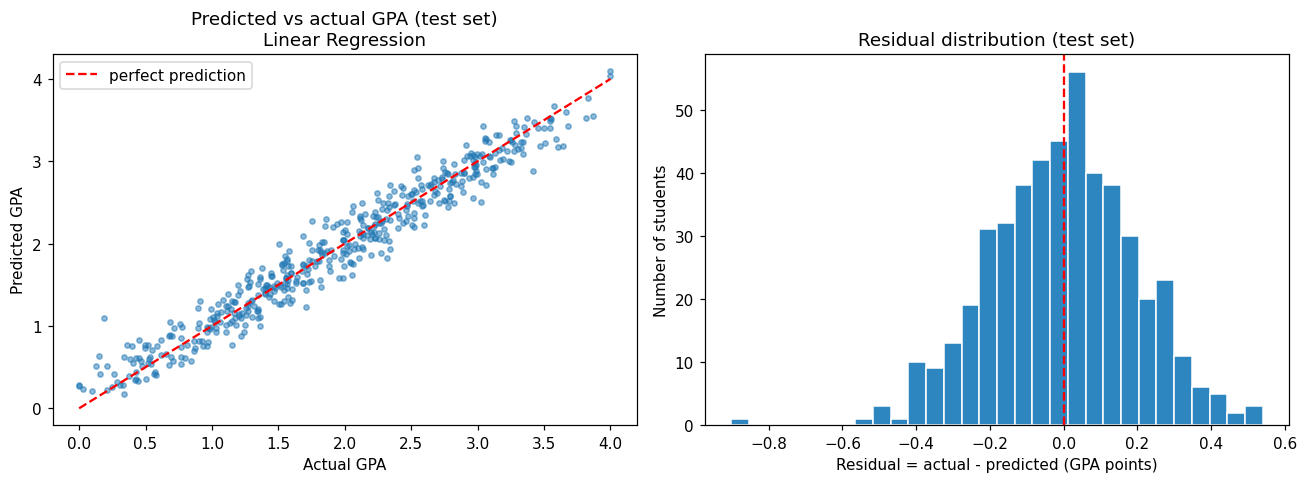

In [19]:
best_model = clone(candidates_reg[best_label]).fit(x_dev, y_dev)
pred_test = best_model.predict(x_test)
resid = y_test - pred_test

print("Winner on the untouched test set -> MAE %.3f | RMSE %.3f | R2 %.3f"
      % (mean_absolute_error(y_test, pred_test), np.sqrt(mean_squared_error(y_test, pred_test)), r2_score(y_test, pred_test)))
print("Share of test predictions within 0.25 GPA points: %.1f%%" % (100 * (resid.abs() <= 0.25).mean()))
print("Share of test predictions within 0.50 GPA points: %.1f%%" % (100 * (resid.abs() <= 0.50).mean()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, pred_test, s=12, alpha=0.5)
axes[0].plot([0, 4], [0, 4], "r--", label="perfect prediction")
axes[0].set_xlabel("Actual GPA"); axes[0].set_ylabel("Predicted GPA")
axes[0].set_title("Predicted vs actual GPA (test set)\n" + best_label); axes[0].legend()
axes[1].hist(resid, bins=30, color="#2e86c1", edgecolor="white")
axes[1].axvline(0, color="r", linestyle="--")
axes[1].set_xlabel("Residual = actual - predicted (GPA points)"); axes[1].set_ylabel("Number of students")
axes[1].set_title("Residual distribution (test set)")
plt.tight_layout(); fig.savefig(OUT_DIR / "predicted_vs_actual_and_residuals.png"); plt.show()

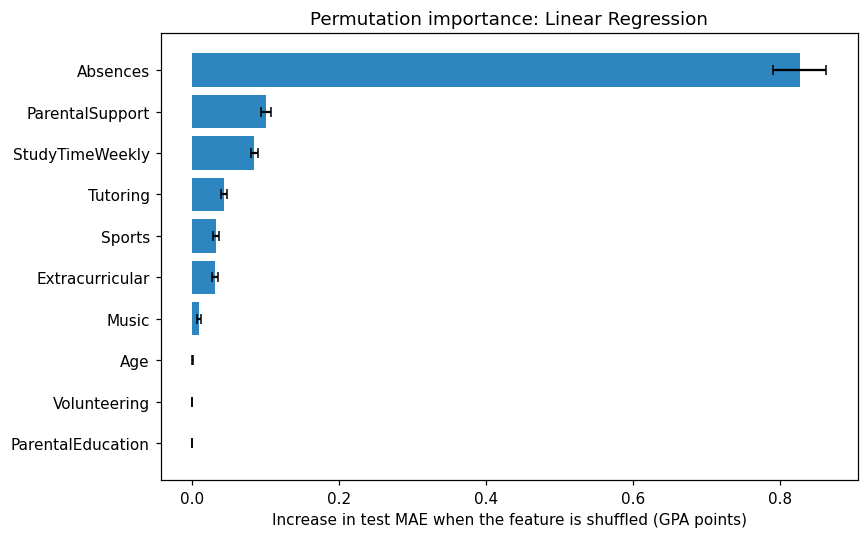

,feature,mae_increase,std
0,Absences,0.8259,0.0364
1,ParentalSupport,0.1006,0.0068
2,StudyTimeWeekly,0.0844,0.0045
3,Tutoring,0.0431,0.0035
4,Sports,0.0326,0.0038
5,Extracurricular,0.0308,0.0037
6,Music,0.0085,0.0026
7,Age,0.0002,0.0002
8,Volunteering,0.0000,0.0001
9,ParentalEducation,0.0000,0.0000


In [20]:
perm = permutation_importance(best_model, x_test, y_test, n_repeats=20, random_state=SEED,
                              scoring="neg_mean_absolute_error", n_jobs=1)
imp = pd.DataFrame({"feature": FEATURES, "mae_increase": perm.importances_mean, "std": perm.importances_std}) \
        .sort_values("mae_increase")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.feature, imp.mae_increase, xerr=imp["std"], color="#2e86c1", capsize=3)
ax.set_xlabel("Increase in test MAE when the feature is shuffled (GPA points)")
ax.set_title("Permutation importance: " + best_label)
plt.tight_layout(); fig.savefig(OUT_DIR / "permutation_importance.png"); plt.show()
imp.sort_values("mae_increase", ascending=False).round(4).reset_index(drop=True)

In [21]:
x_dev_ext = df.loc[x_dev.index, FEATURES + ["Gender", "Ethnicity"]]
res_ext = cross_validate(clone(candidates_reg[best_label]), x_dev_ext, y_dev, cv=cv_reg,
                         scoring="neg_mean_absolute_error", n_jobs=1)
mae_ext = -res_ext["test_score"].mean()
mae_base = results.iloc[0]["cv_mae_mean"]
print("CV MAE with the 10 planned features : %.4f" % mae_base)
print("CV MAE with Gender + Ethnicity added: %.4f   (difference %+.4f)" % (mae_ext, mae_ext - mae_base))
print("\nIf the difference is tiny, excluding the sensitive columns costs nothing, which supports the plan's feature policy.")

CV MAE with the 10 planned features : 0.1603
CV MAE with Gender + Ethnicity added: 0.1604   (difference +0.0002)

If the difference is tiny, excluding the sensitive columns costs nothing, which supports the plan's feature policy.


In [22]:
yc = df["GradeClass_fixed"]
xc_dev, xc_test, yc_dev, yc_test = train_test_split(x, yc, test_size=TEST_SIZE, random_state=SEED, stratify=yc)
cv_clf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=3, random_state=SEED)
scoring_clf = {"acc": "accuracy", "f1": "f1_macro", "bacc": "balanced_accuracy"}

def make_classifiers():
    models = {
        "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        "Decision Tree": DecisionTreeClassifier(random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=N_JOBS),
        "HistGradientBoosting": HistGradientBoostingClassifier(random_state=SEED),
        "SVC (RBF)": make_pipeline(StandardScaler(), SVC()),
    }
    if HAS_XGB:
        models["XGBoost"] = XGBClassifier(random_state=SEED, n_jobs=N_JOBS)
    return models

def run_cv_clf(label, model):
    start = time.perf_counter()
    res = cross_validate(model, xc_dev, yc_dev, cv=cv_clf, scoring=scoring_clf, n_jobs=1)
    return {"model": label, "cv_accuracy": res["test_acc"].mean(), "cv_accuracy_std": res["test_acc"].std(),
            "cv_macro_f1": res["test_f1"].mean(), "cv_balanced_acc": res["test_bacc"].mean(),
            "cv_seconds": time.perf_counter() - start}

clf_default = make_classifiers()
cv_clf_default = pd.DataFrame([run_cv_clf(n, m) for n, m in clf_default.items()]) \
                   .sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
cv_clf_default.round(4)

,model,cv_accuracy,cv_accuracy_std,cv_macro_f1,cv_balanced_acc,cv_seconds
0,Logistic Regression,0.8181,0.0221,0.6726,0.6623,1.0789
1,XGBoost,0.7597,0.0133,0.6136,0.6065,10.5837
2,HistGradientBoosting,0.7569,0.0240,0.6099,0.5991,31.6450
3,Random Forest,0.7670,0.0196,0.6011,0.5876,22.5469
4,Decision Tree,0.7174,0.0234,0.5648,0.5690,0.5272
5,SVC (RBF),0.7688,0.0222,0.5531,0.5606,2.7729
6,Dummy (majority),0.5327,0.0008,0.1390,0.2000,0.1771


In [23]:
# Tune the two best real classifiers (by macro-F1) and re-score them on the same folds
clf_grids = {
    "Logistic Regression": {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
    "Decision Tree": {"max_depth": [3, 4, 5, 6, 8, None], "min_samples_leaf": [1, 5, 10, 20, 40]},
    "Random Forest": {"n_estimators": [200, 300, 500], "max_depth": [None, 6, 10, 14],
                      "min_samples_leaf": [1, 2, 5, 10], "max_features": ["sqrt", 0.6, 1.0]},
    "HistGradientBoosting": {"learning_rate": [0.01, 0.03, 0.05, 0.1], "max_iter": [100, 200, 400],
                             "max_depth": [None, 3, 5], "min_samples_leaf": [10, 20, 40],
                             "l2_regularization": [0, 0.1, 1, 10]},
    "SVC (RBF)": {"svc__C": [0.1, 1, 3, 10, 30], "svc__gamma": ["scale", 0.01, 0.03, 0.1]},
}
if HAS_XGB:
    clf_grids["XGBoost"] = {"n_estimators": [200, 400], "learning_rate": [0.03, 0.05, 0.1],
                            "max_depth": [2, 3, 4, 6], "subsample": [0.7, 0.85, 1.0],
                            "colsample_bytree": [0.7, 0.85, 1.0], "reg_lambda": [1, 5, 10]}

top_two = [m for m in cv_clf_default.model if not m.startswith("Dummy")][:2]
search_cv_clf = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=1, random_state=SEED)
clf_tuned, clf_best_params = {}, {}
for name in top_two:
    if name not in clf_grids:
        continue
    start = time.perf_counter()
    s = RandomizedSearchCV(make_classifiers()[name], clf_grids[name], n_iter=12, cv=search_cv_clf,
                           scoring="f1_macro", random_state=SEED, n_jobs=1, refit=True)
    s.fit(xc_dev, yc_dev)
    clf_tuned[name] = clone(s.best_estimator_)
    clf_best_params[name] = {k: (v if isinstance(v, (int, float, str, type(None))) else str(v)) for k, v in s.best_params_.items()}
    print("%-22s search macro-F1 %.4f | %.0fs | %s" % (name, s.best_score_, time.perf_counter() - start, clf_best_params[name]))

cv_clf_tuned = pd.DataFrame([run_cv_clf(n + " (tuned)", m) for n, m in clf_tuned.items()])

Logistic Regression    search macro-F1 0.7298 | 2s | {'logisticregression__C': 10}
XGBoost                search macro-F1 0.6380 | 111s | {'subsample': 1.0, 'reg_lambda': 5, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


In [24]:
clf_candidates = dict(clf_default)
for name, est in clf_tuned.items():
    clf_candidates[name + " (tuned)"] = est

def holdout_clf(model):
    fitted = clone(model).fit(xc_dev, yc_dev)
    p = fitted.predict(xc_test)
    return {"test_accuracy": accuracy_score(yc_test, p), "test_macro_f1": f1_score(yc_test, p, average="macro"),
            "test_balanced_acc": balanced_accuracy_score(yc_test, p)}

clf_test = pd.DataFrame({k: holdout_clf(v) for k, v in clf_candidates.items()}).T.reset_index().rename(columns={"index": "model"})
clf_results = pd.concat([cv_clf_default, cv_clf_tuned], ignore_index=True).merge(clf_test, on="model") \
                .sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
clf_results.insert(0, "rank", clf_results.index + 1)
clf_results.to_csv(OUT_DIR / "classification_results.csv", index=False)
clf_results[["rank", "model", "cv_accuracy", "cv_accuracy_std", "cv_macro_f1", "cv_balanced_acc",
             "test_accuracy", "test_macro_f1", "test_balanced_acc"]].round(4)

,rank,model,cv_accuracy,cv_accuracy_std,cv_macro_f1,cv_balanced_acc,test_accuracy,test_macro_f1,test_balanced_acc
0,1,Logistic Regression (tuned),0.8244,0.0190,0.7215,0.7140,0.8163,0.7082,0.6945
1,2,Logistic Regression,0.8181,0.0221,0.6726,0.6623,0.8225,0.7071,0.6879
2,3,XGBoost (tuned),0.7662,0.0163,0.6211,0.6112,0.7912,0.6582,0.6471
3,4,XGBoost,0.7597,0.0133,0.6136,0.6065,0.7871,0.6594,0.6528
4,5,HistGradientBoosting,0.7569,0.0240,0.6099,0.5991,0.7829,0.6607,0.6439
5,6,Random Forest,0.7670,0.0196,0.6011,0.5876,0.7933,0.6494,0.6387
6,7,Decision Tree,0.7174,0.0234,0.5648,0.5690,0.7056,0.5641,0.5668
7,8,SVC (RBF),0.7688,0.0222,0.5531,0.5606,0.7933,0.6006,0.6078
8,9,Dummy (majority),0.5327,0.0008,0.1390,0.2000,0.5324,0.1390,0.2000


Best classifier by CV macro-F1: Logistic Regression (tuned)
              precision    recall  f1-score   support

           A      0.778     0.467     0.583        15
           B      0.648     0.714     0.680        49
           C      0.658     0.623     0.640        77
           D      0.652     0.723     0.686        83
           F      0.960     0.945     0.953       255

    accuracy                          0.816       479
   macro avg      0.739     0.694     0.708       479
weighted avg      0.821     0.816     0.817       479



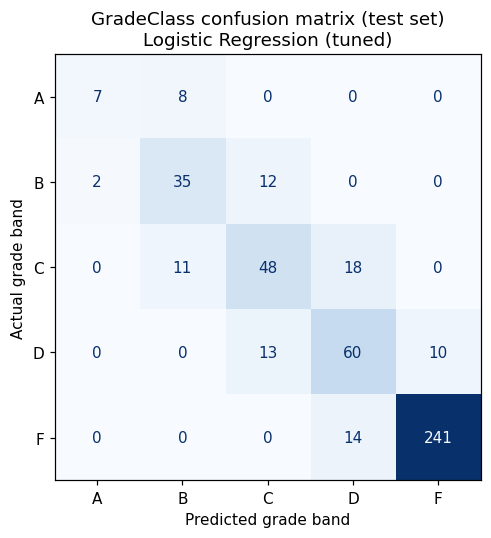

In [25]:
best_clf_label = clf_results.iloc[0]["model"]
best_clf = clone(clf_candidates[best_clf_label]).fit(xc_dev, yc_dev)
pc = best_clf.predict(xc_test)
names = ["A", "B", "C", "D", "F"]
print("Best classifier by CV macro-F1:", best_clf_label)
print(classification_report(yc_test, pc, target_names=names, digits=3))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(yc_test, pc), display_labels=names).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("GradeClass confusion matrix (test set)\n" + best_clf_label)
ax.set_xlabel("Predicted grade band"); ax.set_ylabel("Actual grade band")
plt.tight_layout(); fig.savefig(OUT_DIR / "confusion_matrix.png"); plt.show()

In [26]:
r = results.iloc[0]
print("=" * 70)
print("REGRESSION (predict GPA)")
print("  Use            :", r.model)
print("  CV MAE         : %.3f +/- %.3f GPA points (50 folds)" % (r.cv_mae_mean, r.cv_mae_std))
print("  CV R2          : %.3f" % r.cv_r2_mean)
print("  Test MAE / R2  : %.3f / %.3f" % (r.test_mae, r.test_r2))
print("  Baseline MAE   : %.3f (predict the mean)" % results.loc[results.model == "Dummy (mean)", "cv_mae_mean"].iloc[0])
print("  Parameters     :", r.selected_parameters)
c = clf_results.iloc[0]
print("\nCLASSIFICATION (predict GradeClass A-F)")
print("  Use            :", c.model)
print("  CV accuracy    : %.3f | macro-F1 %.3f | balanced acc %.3f" % (c.cv_accuracy, c.cv_macro_f1, c.cv_balanced_acc))
print("  Test accuracy  : %.3f | macro-F1 %.3f" % (c.test_accuracy, c.test_macro_f1))
print("=" * 70)

joblib.dump(best_model, OUT_DIR / "best_gpa_model.joblib")
meta = {"model": r.model, "seed": SEED, "features": FEATURES, "target": TARGET,
        "cv_mae_mean": float(r.cv_mae_mean), "test_mae": float(r.test_mae), "test_r2": float(r.test_r2),
        "parameters": r.selected_parameters, "trained_on_rows": int(len(x_dev)),
        "gpa_range_in_data": [float(df[TARGET].min()), float(df[TARGET].max())]}
(OUT_DIR / "model_metadata.json").write_text(json.dumps(meta, indent=2))
print("\nSaved to", OUT_DIR.resolve(), ":", sorted(p.name for p in OUT_DIR.iterdir()))

REGRESSION (predict GPA)
  Use            : Linear Regression
  CV MAE         : 0.160 +/- 0.005 GPA points (50 folds)
  CV R2          : 0.953
  Test MAE / R2  : 0.155 / 0.953
  Baseline MAE   : 0.774 (predict the mean)
  Parameters     : defaults

CLASSIFICATION (predict GradeClass A-F)
  Use            : Logistic Regression (tuned)
  CV accuracy    : 0.824 | macro-F1 0.722 | balanced acc 0.714
  Test accuracy  : 0.816 | macro-F1 0.708

Saved to C:\Users\DELL\Downloads\project\outputs_notebook : ['best_gpa_model.joblib', 'classification_results.csv', 'confusion_matrix.png', 'cv_mae_by_model.png', 'model_comparison.csv', 'model_metadata.json', 'permutation_importance.png', 'predicted_vs_actual_and_residuals.png']
